# Week 04 ? Task 05: Bonus ? seasonal swing versus growth

**Dataset:** UCI Machine Learning Repository, Bike Sharing Dataset, `day.csv`.

**Source:** [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), downloaded **20 October 2026**. The source contains daily bike rentals (`cnt`) from Capital Bikeshare for 2011?2012 and a categorical `season` field.

The daily count is a flow, so I aggregate it by month with `sum()`, producing 24 regular monthly observations. The question is whether the seasonal swing grows in absolute units because the system grows, or whether it also grows proportionally.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

DATA = Path.cwd()
if not (DATA / "bike_sharing_dataset" / "day.csv").exists():
    DATA = Path(r"D:\University\ML Lab\Week04")
SOURCE_URL = "https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset"
DOWNLOAD_DATE = "2026-10-20"
plt.style.use("seaborn-v0_8-whitegrid")

## Audit and regular monthly series

In [2]:
daily = pd.read_csv(DATA / "bike_sharing_dataset" / "day.csv", parse_dates=["dteday"])
daily = daily.set_index("dteday").sort_index()
season_names = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
daily["season_name"] = daily["season"].map(season_names)

index = daily.index
expected = pd.date_range(index.min(), index.max(), freq="D")
audit = {
    "sorted": index.is_monotonic_increasing,
    "duplicates": int(index.duplicated().sum()),
    "gaps": int(len(expected.difference(index))),
    "n_daily": len(index), "start": index.min(), "end": index.max()
}
print("tslib.audit_index-compatible audit:", audit)
assert audit["sorted"] and audit["duplicates"] == 0 and audit["gaps"] == 0

monthly = daily["cnt"].resample("MS").sum().astype(float)
assert len(monthly) == 24
print("Monthly flow series:", monthly.index.min().date(), "to", monthly.index.max().date(), "n =", len(monthly))

tslib.audit_index-compatible audit: {'sorted': True, 'duplicates': 0, 'gaps': 0, 'n_daily': 731, 'start': Timestamp('2011-01-01 00:00:00'), 'end': Timestamp('2012-12-31 00:00:00')}
Monthly flow series: 2011-01-01 to 2012-12-01 n = 24


## Bank the series to 45?

For a plot of monthly flow, the figure height/width is chosen so the median absolute month-to-month slope is shown at approximately 45?. The computed aspect ratio is stated explicitly.

Median absolute month-to-month slope: 10,026.0 rentals/month
45-degree banked figsize: (11.00, 8.60) inches; height/width = 0.782


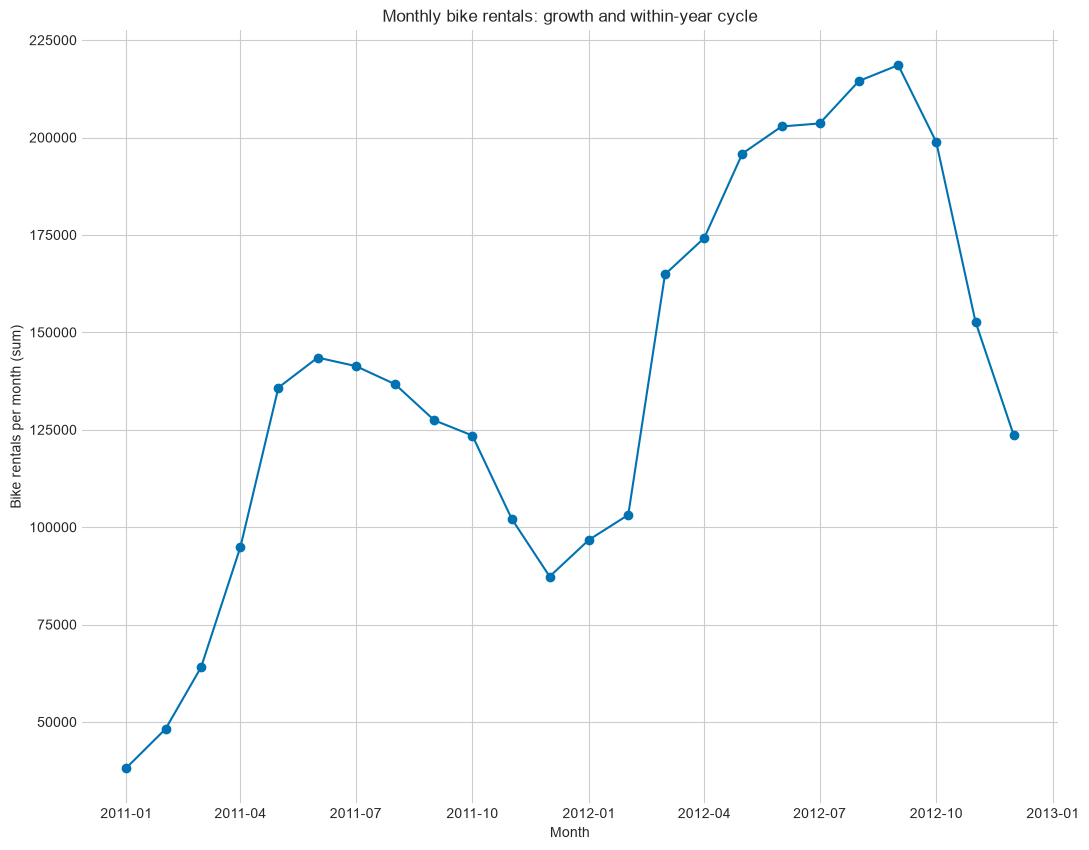

In [3]:
median_abs_slope = monthly.diff().abs().median()
x_range = len(monthly) - 1
y_range = monthly.max() - monthly.min()
width = 11.0
height = width * y_range / (x_range * median_abs_slope)
print(f"Median absolute month-to-month slope: {median_abs_slope:,.1f} rentals/month")
print(f"45-degree banked figsize: ({width:.2f}, {height:.2f}) inches; height/width = {height/width:.3f}")

fig, ax = plt.subplots(figsize=(width, height))
ax.plot(monthly.index, monthly, marker="o", color="#0072B2")
ax.set(title="Monthly bike rentals: growth and within-year cycle", xlabel="Month", ylabel="Bike rentals per month (sum)")
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
fig.tight_layout(); plt.show(); plt.close(fig)

## Cycle plot by month

The cycle plot places both years on the same January?December horizontal cycle. The `season` category is retained from the source and shown by its named season bands.

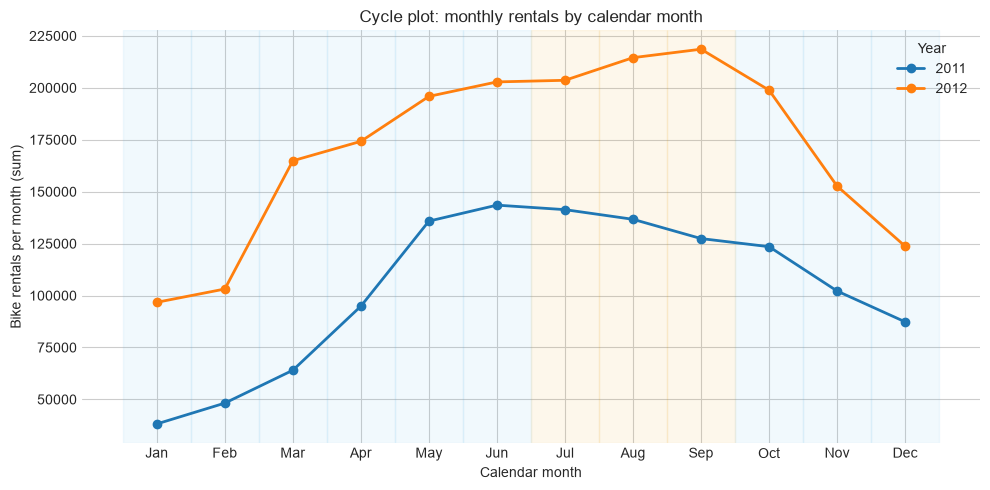

Modal month categories: {1: 'Winter', 2: 'Winter', 3: 'Winter', 4: 'Spring', 5: 'Spring', 6: 'Spring', 7: 'Summer', 8: 'Summer', 9: 'Summer', 10: 'Fall', 11: 'Fall', 12: 'Fall'}


In [4]:
cycle = monthly.rename("rentals").to_frame()
cycle["year"] = cycle.index.year
cycle["month"] = cycle.index.month
cycle["month_name"] = cycle.index.strftime("%b")
# Source season is daily; use the modal source category within each calendar month.
month_season = daily["season_name"].groupby(daily.index.month).agg(lambda x: x.mode().iat[0])
fig, ax = plt.subplots(figsize=(10, 5))
for year, group in cycle.groupby("year"):
    ax.plot(group["month"], group["rentals"], marker="o", linewidth=2, label=str(year))
for month in range(1, 13):
    ax.axvspan(month - .5, month + .5, color="#E69F00" if month_season[month] == "Summer" else "#56B4E9", alpha=.08)
ax.set_xticks(range(1, 13)); ax.set_xticklabels([pd.Timestamp(2020, m, 1).strftime("%b") for m in range(1, 13)])
ax.set(title="Cycle plot: monthly rentals by calendar month", xlabel="Calendar month", ylabel="Bike rentals per month (sum)")
ax.legend(title="Year", frameon=False); ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
fig.tight_layout(); plt.show(); plt.close(fig)
print("Modal month categories:", month_season.to_dict())

## Additive versus multiplicative decomposition residuals

The decomposition period is 12 months. The residual panels answer whether the unexplained error is more stable in absolute units (additive) or in relative units (multiplicative).

In [5]:
def classical_decompose(series, period=12, model="additive"):
    trend = series.rolling(period, center=True).mean()
    if model == "additive":
        detrended = series - trend
        pattern = detrended.groupby(detrended.index.month).mean()
        pattern = pattern - pattern.mean()
        seasonal = pd.Series([pattern[t.month] for t in series.index], index=series.index)
        residual = series - trend - seasonal
    elif model == "multiplicative":
        detrended = series / trend
        pattern = detrended.groupby(detrended.index.month).mean()
        pattern = pattern / pattern.mean()
        seasonal = pd.Series([pattern[t.month] for t in series.index], index=series.index)
        residual = series / (trend * seasonal)
    else:
        raise ValueError("model must be additive or multiplicative")
    return trend, seasonal, residual

add_trend, add_seasonal, add_resid = classical_decompose(monthly, model="additive")
mult_trend, mult_seasonal, mult_resid = classical_decompose(monthly, model="multiplicative")
print("Additive seasonal amplitude:", add_seasonal.max() - add_seasonal.min())
print("Additive residual SD:", add_resid.dropna().std())
print("Multiplicative seasonal ratio amplitude:", mult_seasonal.max() - mult_seasonal.min())
print("Multiplicative residual SD:", mult_resid.dropna().std())

Additive seasonal amplitude: 81023.375
Additive residual SD: 1008.3902877911767
Multiplicative seasonal ratio amplitude: 0.6131514912160068
Multiplicative residual SD: 0.027913990502797623


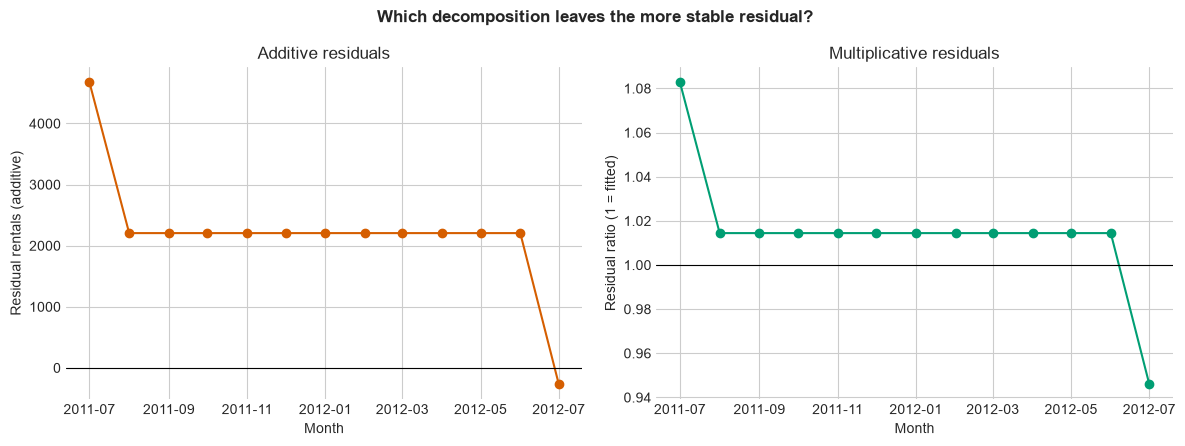

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
axes[0].plot(add_resid, marker="o", color="#D55E00")
axes[0].axhline(0, color="black", linewidth=.8)
axes[0].set(title="Additive residuals", xlabel="Month", ylabel="Residual rentals (additive)")
axes[1].plot(mult_resid, marker="o", color="#009E73")
axes[1].axhline(1, color="black", linewidth=.8)
axes[1].set(title="Multiplicative residuals", xlabel="Month", ylabel="Residual ratio (1 = fitted)")
for ax in axes: ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
fig.suptitle("Which decomposition leaves the more stable residual?", fontweight="bold")
fig.tight_layout(); plt.show(); plt.close(fig)

## Answer

The seasonal swing is mostly a growth-scaled effect: the additive seasonal amplitude is **81,023.4 rentals**, while the multiplicative residual standard deviation is only **0.0279** (about 2.8% of fitted values), compared with an additive residual standard deviation of **1,008.4 rentals**. The multiplicative decomposition therefore settles that the apparent increase in seasonal amplitude is primarily because the bike-share system grew, not because the seasonality became proportionally stronger.